# Length of stay: Gradient boosting

Histogram-based gradient boosting, scikit-learn's fast implementation of boosted trees (same idea as `GradientBoostingClassifier` / XGBoost / LightGBM). Trees are fit one after another to the previous ensemble's errors. Defaults: 100 iterations, learning rate 0.1, up to 31 leaves per tree, and early stopping on a 10% internal validation split because n > 10k.

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier

model = HistGradientBoostingClassifier(random_state=utils.SEED)
model

,loss,'log_loss'
,learning_rate,0.1
,max_iter,100
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


== Gradient boosting ==  macro-F1 0.360  accuracy 0.528
              precision    recall  f1-score   support

     <1 week       0.58      0.78      0.67      4554
   1-4 weeks       0.45      0.46      0.45      3420
  1-3 months       0.50      0.21      0.30      2017
   3+ months       0.26      0.01      0.02       553

    accuracy                           0.53     10544
   macro avg       0.45      0.37      0.36     10544
weighted avg       0.50      0.53      0.49     10544

quadratic weighted kappa: 0.301


train accuracy 0.638  |  fit 25.1s  predict 0.2s


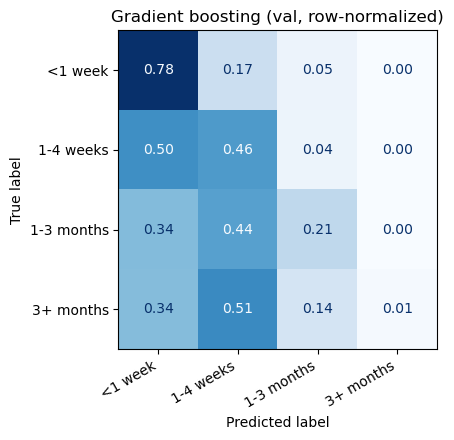

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="Gradient boosting",
                                           results_dir=RESULTS_DIR)

## Hyperparameter tuning (light–medium)

**Randomized search with a time-ordered inner split** (`utils.tune_classifier`):
- Training years are split again, by time and grouped by animal: candidates are fit on intakes before 2021 and scored on 2021 intakes.
- Candidates are ranked by **macro-F1**, so all four bins count equally, not just the dominant `<1 week`.
- The best setting is then refit on the full training set (< 2022) and scored on the **same 2022 val set** as the untuned model.
- Neither val nor test is seen during the search, so the comparison below is fair.

Searched: learning rate, number of rounds, tree size, leaf size, L2 penalty, and class weighting.

In [4]:
from scipy.stats import loguniform

base = utils.with_params(model, {})  # unfitted copy of the untuned model
space = {
    'learning_rate': loguniform(0.02, 0.3),
    'max_iter': [100, 200, 400],          # boosting rounds (early stopping still on)
    'max_leaf_nodes': [15, 31, 63, 127],
    'min_samples_leaf': [20, 50, 100, 200],
    'l2_regularization': loguniform(1e-3, 10),
    'class_weight': [None, 'balanced'],
}

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="Gradient boosting (tuned)", n_iter=20, results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 592 rows (0.5%) belonging to animals first seen in an earlier split


Gradient boosting (tuned): 20 candidates in 8.3 min | sub-train 115,479, inner-val 10,687 | best inner-val f1_macro 0.382
best params: {'class_weight': None, 'l2_regularization': 0.03387255565852149, 'learning_rate': 0.2866812213933528, 'max_iter': 100, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}


,class_weight,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,inner_val_f1_macro,mean_fit_time
0,None,0.033873,0.286681,100,63,20,0.381767,55.484496
1,None,0.035868,0.041702,100,127,50,0.380323,132.454805
2,None,0.001978,0.052798,100,127,100,0.379559,127.119048
3,None,0.526296,0.067742,200,127,20,0.377358,173.668663
4,None,0.311310,0.049000,400,63,50,0.377078,291.620907
5,None,0.001987,0.289534,100,127,200,0.373077,63.760369
6,None,4.337921,0.040307,200,31,50,0.369252,179.122645
7,balanced,0.009207,0.127236,100,127,100,0.361184,81.939362
8,None,0.013297,0.086954,100,15,100,0.360476,77.969611
9,None,0.002259,0.034004,100,31,200,0.358283,110.180799


== Gradient boosting (tuned) ==  macro-F1 0.383  accuracy 0.517
              precision    recall  f1-score   support

     <1 week       0.58      0.74      0.65      4554
   1-4 weeks       0.44      0.45      0.45      3420
  1-3 months       0.47      0.24      0.32      2017
   3+ months       0.25      0.07      0.11       553

    accuracy                           0.52     10544
   macro avg       0.43      0.38      0.38     10544
weighted avg       0.50      0.52      0.49     10544

quadratic weighted kappa: 0.314


train accuracy 0.690  |  fit 23.7s  predict 0.1s


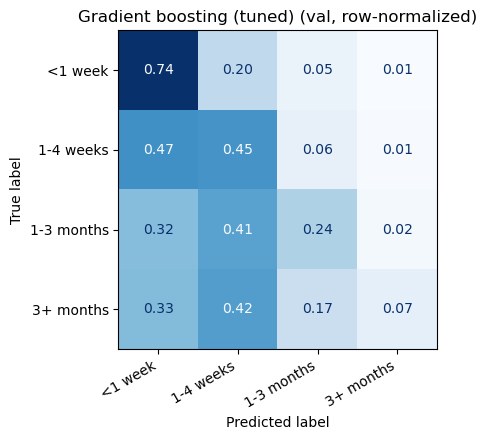

In [5]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="Gradient boosting (tuned)", results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [6]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "qwk", "train_accuracy"]
    + [f"recall_{c}" for c in utils.LOS_BIN_LABELS]].round(3)

,accuracy,macro_f1,qwk,train_accuracy,recall_<1 week,recall_1-4 weeks,recall_1-3 months,recall_3+ months
model,,,,,,,,
Gradient boosting,0.528,0.360,0.301,0.638,0.780,0.461,0.213,0.013
Gradient boosting (tuned),0.517,0.383,0.314,0.690,0.738,0.455,0.244,0.074
